# Phase 5B • พยากรณ์ความผันผวนและทิศทางผลตอบแทน

ใช้ TDEX.BK เป็นตัวอย่างพยากรณ์ตลาด และใช้หุ้นไทย 16 ตัวในช่วงเดียวกับ Phase 5 เพื่อตรวจว่าค่าพยากรณ์ช่วยจัดพอร์ตได้หรือไม่ ทุก forecast ใช้ข้อมูลถึงสิ้นวัน `t` และวัดผลใน 5 วันซื้อขายถัดไป

เปิดจากด้านบนแล้ว Run All โดยใช้ kernel `.venv` ของโปรเจกต์ รุ่นที่ใช้รันคือ arch 9.0.0, LightGBM 4.7.0, PyTorch 2.15.0 และ scikit-learn 1.9.1 หากตั้ง environment ใหม่บน macOS ต้องมี OpenMP สำหรับ LightGBM ด้วย

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
project_root = next(
    (path for path in (cwd, cwd.parent, cwd / "Thai_Equity_Portfolio")
     if (path / "src" / "data.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("เปิด notebook จากโฟลเดอร์โปรเจกต์หรือ notebooks/")
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from arch import arch_model
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

from src.data import load_price_matrix
from src.portfolio import get_equal_weights, get_inverse_vol_weights
from src.risk import calculate_annualized_volatility, calculate_max_drawdown, calculate_sharpe_ratio

HORIZON = 5
SEQUENCE_LENGTH = 20
SEED = 42
VALIDATION_START = pd.Timestamp("2017-01-01")
TEST_START = pd.Timestamp("2018-01-01")
torch.set_num_threads(1)
torch.manual_seed(SEED)

prices = load_price_matrix().sort_index()
returns = prices.pct_change(fill_method=None).dropna()
market = returns["TDEX.BK"] * 100  # หน่วย % เช่น 1.2 หมายถึง 1.2%
stocks = returns.drop(columns="TDEX.BK")  # หน่วยทศนิยมสำหรับ backtest
selection_date = returns.index[returns.index < TEST_START][-2]
print(f"{stocks.shape[1]} หุ้น + TDEX.BK | {returns.index.min().date()} ถึง {returns.index.max().date()}")

pre_test_dates = returns.index[returns.index < TEST_START]
print("สามจุดเวลาแรกของการจัดพอร์ต")
display(pd.DataFrame({
    "วันที่": [selection_date, pre_test_dates[-1], returns.index[returns.index >= TEST_START][0]],
    "เลือกจาก index": ["[-2] ก่อน TEST_START", "[-1] ก่อน TEST_START", "[0] ตั้งแต่ TEST_START"],
    "สิ่งที่ทำ": ["ออกสัญญาณหลังตลาดปิด", "ปรับพอร์ตที่ราคาปิด", "เริ่มนับผลตอบแทน"],
}))
print("ตัวอย่างราคาและผลตอบแทนรายวันของ TDEX.BK")
display(pd.DataFrame({"Adjusted close": prices["TDEX.BK"], "Return (%)": market}).head(5).round(4))

16 หุ้น + TDEX.BK | 2015-01-06 ถึง 2024-12-30
สามจุดเวลาแรกของการจัดพอร์ต


,วันที่,เลือกจาก index,สิ่งที่ทำ
0,2017-12-28,[-2] ก่อน TEST_START,ออกสัญญาณหลังตลาดปิด
1,2017-12-29,[-1] ก่อน TEST_START,ปรับพอร์ตที่ราคาปิด
2,2018-01-03,[0] ตั้งแต่ TEST_START,เริ่มนับผลตอบแทน


ตัวอย่างราคาและผลตอบแทนรายวันของ TDEX.BK


,Adjusted close,Return (%)
date,,
2015-01-05,6.0574,NaN
2015-01-06,6.0393,-0.2982
2015-01-07,6.0815,0.6979
2015-01-08,6.1658,1.3862
2015-01-09,6.1839,0.2929


## 1. สร้าง target แล้วตรวจด้วยตัวอย่างหนึ่งวัน

Realized volatility คือรากที่สองของผลรวมผลตอบแทนรายวันกำลังสอง หน่วยเป็น % ตลอด 5 วัน ส่วน target ทิศทางเป็น 1 เมื่อผลตอบแทนทบต้นตลอด 5 วันสูงกว่า 0 และเป็น 0 เมื่อทรงตัวหรือลดลง

In [2]:
def target_components(series):
    future = pd.concat({f"t+{k}": series.shift(-k) for k in range(1, HORIZON + 1)}, axis=1)
    future_vol = np.sqrt(future.pow(2).sum(axis=1, min_count=HORIZON))
    growth = (1 + future / 100).prod(axis=1, min_count=HORIZON)
    return future, future_vol, growth


def make_targets(series):
    _, future_vol, growth = target_components(series)
    label_end = series.index.to_series().shift(-HORIZON)
    return pd.DataFrame({
        "realized_vol": future_vol,
        "direction_up": growth.gt(1).where(growth.notna()),
        "label_end": label_end,
    })


market_targets = make_targets(market)
example_pos = returns.index.searchsorted(TEST_START)
example_day = returns.index[example_pos]
example_future = market.iloc[example_pos + 1:example_pos + 1 + HORIZON]
example_target = market_targets.loc[example_day]
assert example_future.index[-1] == example_target["label_end"]
assert np.isclose(np.sqrt((example_future**2).sum()), example_target["realized_vol"])

future, future_vol, growth = target_components(market)
sample_days = market.index[example_pos:example_pos + 3]

print("1) future จาก shift(-k) แถวนึงคือวันที่ t ส่วนคอลัมน์คือผลตอบแทนของวันถัดไป (%)")
display(future.loc[sample_days].round(4).rename_axis("วัน t"))
print(f"2) ไล่คำนวณทีละวันสำหรับ t = {example_day.date()}")
steps = pd.DataFrame({
    "วันซื้อขายจริง": example_future.index,
    "r (%)": example_future.to_numpy(),
}, index=future.columns)
steps["r² (%²)"] = steps["r (%)"] ** 2
steps["1 + r/100"] = 1 + steps["r (%)"] / 100
display(steps.round({"r (%)": 6, "r² (%²)": 6, "1 + r/100": 6}).rename_axis("วันในอนาคต"))

row = future.loc[example_day]
print(f"3) future_vol = √{(row**2).sum():.6f} = {future_vol.loc[example_day]:.6f}%")
print(f"4) growth = ผลคูณของ 1 + r/100 = {growth.loc[example_day]:.6f}")
print(f"   ผลตอบแทนทบต้น = {(growth.loc[example_day] - 1) * 100:+.4f}% → direction_up = {int(example_target['direction_up'])}")
print("5) ตาราง target ที่ใช้จริง")
target_preview = market_targets.loc[sample_days].copy()
target_preview.insert(1, "growth (มูลค่าเงิน 1 บาท)", growth.loc[sample_days])
display(target_preview.round({"realized_vol": 6, "growth (มูลค่าเงิน 1 บาท)": 6}).rename_axis("วัน t"))
print("5 แถวท้ายขาดข้อมูลอนาคต จึงเก็บไว้ใช้พยากรณ์ได้ แต่ยังนำไปวัดผลไม่ได้")
display(future.join(market_targets).tail(HORIZON).round({"realized_vol": 4}))

1) future จาก shift(-k) แถวนึงคือวันที่ t ส่วนคอลัมน์คือผลตอบแทนของวันถัดไป (%)


,t+1,t+2,t+3,t+4,t+5
วัน t,,,,,
2018-01-03,1.0508,0.1733,-0.0865,0.0866,-0.0865
2018-01-04,0.1733,-0.0865,0.0866,-0.0865,0.3463
2018-01-05,-0.0865,0.0866,-0.0865,0.3463,0.4314


2) ไล่คำนวณทีละวันสำหรับ t = 2018-01-03


,วันซื้อขายจริง,r (%),r² (%²),1 + r/100
วันในอนาคต,,,,
t+1,2018-01-04,1.050810,1.104201,1.010508
t+2,2018-01-05,0.173309,0.030036,1.001733
t+3,2018-01-08,-0.086514,0.007485,0.999135
t+4,2018-01-09,0.086589,0.007498,1.000866
t+5,2018-01-10,-0.086514,0.007485,0.999135


3) future_vol = √1.156704 = 1.075502%
4) growth = ผลคูณของ 1 + r/100 = 1.011384
   ผลตอบแทนทบต้น = +1.1384% → direction_up = 1
5) ตาราง target ที่ใช้จริง


,realized_vol,growth (มูลค่าเงิน 1 บาท),direction_up,label_end
วัน t,,,,
2018-01-03,1.075502,1.011384,True,2018-01-10
2018-01-04,0.415267,1.004333,True,2018-01-11
2018-01-05,0.573182,1.006921,True,2018-01-12


5 แถวท้ายขาดข้อมูลอนาคต จึงเก็บไว้ใช้พยากรณ์ได้ แต่ยังนำไปวัดผลไม่ได้


,t+1,t+2,t+3,t+4,t+5,realized_vol,direction_up,label_end
date,,,,,,,,
2024-12-24,0.561797,-0.558659,0.561797,-0.111729,NaN,NaN,NaN,NaT
2024-12-25,-0.558659,0.561797,-0.111729,NaN,NaN,NaN,NaN,NaT
2024-12-26,0.561797,-0.111729,NaN,NaN,NaN,NaN,NaN,NaT
2024-12-27,-0.111729,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2024-12-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT


In [3]:
# แสดง Series ทั้งสองตัวครบทุกวัน รวมแถวท้ายที่ยังรู้ผลไม่ครบ 5 วัน
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    print(f"future_vol — ความผันผวนจริง 5 วันถัดไป (%) | {len(future_vol):,} แถว")
    display(future_vol.rename("future_vol (%)").rename_axis("วัน t").to_frame())

    print(f"growth — มูลค่าเงิน 1 บาทหลังผ่าน 5 วัน | {len(growth):,} แถว")
    display(growth.rename("growth (บาท)").rename_axis("วัน t").to_frame())

future_vol — ความผันผวนจริง 5 วันถัดไป (%) | 2,429 แถว


,future_vol (%)
วัน t,
2015-01-06,1.638191
2015-01-07,1.673623
2015-01-08,0.958093
2015-01-09,0.958181
2015-01-12,1.314368
2015-01-13,1.314396
2015-01-14,1.059820
2015-01-15,2.121540
2015-01-16,3.630614


growth — มูลค่าเงิน 1 บาทหลังผ่าน 5 วัน | 2,429 แถว


,growth (บาท)
วัน t,
2015-01-06,1.025922
2015-01-07,1.010891
2015-01-08,0.999023
2015-01-09,0.993184
2015-01-12,0.999030
2015-01-13,0.999028
2015-01-14,1.006856
2015-01-15,1.023461
2015-01-16,1.056862


## 2. สร้าง features และ baseline

Historical ใช้ค่าเฉลี่ยของผลตอบแทนกำลังสองย้อนหลัง 20 วัน ส่วน EWMA ให้น้ำหนักมากขึ้นกับวันล่าสุด ทั้งคู่คูณความแปรปรวนรายวันด้วย 5 ก่อนถอดรากเพื่อให้หน่วยเท่ากับ target ฟีเจอร์ทุกตัวใช้ข้อมูลถึงวันออก forecast เท่านั้น

In [4]:
def make_features(series):
    squared = series.pow(2)
    return pd.DataFrame({
        "return_t": series,
        "return_lag_1": series.shift(1),
        "return_mean_5": series.rolling(5).mean(),
        "return_mean_20": series.rolling(20).mean(),
        "vol_hist": np.sqrt(HORIZON * squared.rolling(20).mean()),
        "vol_ewma": np.sqrt(HORIZON * squared.ewm(alpha=0.06, adjust=False).mean()),
        "vol_short": np.sqrt(HORIZON * squared.rolling(5).mean()),
    })


market_features = make_features(market)
feature_cols = market_features.columns.tolist()
stock_panel = pd.concat(
    {
        ticker: make_features(stocks[ticker] * 100).join(make_targets(stocks[ticker] * 100))
        for ticker in stocks
    },
    names=["ticker", "date"],
).reorder_levels(["date", "ticker"]).sort_index()
panel_dates = stock_panel.index.get_level_values("date")
stock_features_ready = stock_panel[feature_cols].notna().all(axis=1)
sequences = pd.concat(
    [market.shift(k) for k in range(SEQUENCE_LENGTH - 1, -1, -1)], axis=1
)
sequences.columns = [f"lag_{k}" for k in range(SEQUENCE_LENGTH - 1, -1, -1)]
ready = market_features.notna().all(axis=1) & sequences.notna().all(axis=1)

print(f"LSTM อ่าน {SEQUENCE_LENGTH} วัน เรียงจากเก่าสุดถึงวัน t")
display(market_features.loc[[example_day]].round(4))
display(sequences.loc[[example_day], ["lag_19", "lag_1", "lag_0"]].round(4))

past_returns = market.loc[:example_day].tail(SEQUENCE_LENGTH)
hist_daily_variance = past_returns.pow(2).mean()
ewma_daily_variance = market.loc[:example_day].pow(2).ewm(alpha=0.06, adjust=False).mean().iloc[-1]
print(f"คำนวณ baseline ณ {example_day.date()} ด้วยข้อมูลถึงวัน t")
baseline_steps = pd.DataFrame({
    "Daily variance (%²)": [hist_daily_variance, ewma_daily_variance],
    "5-day variance (%²)": HORIZON * np.array([hist_daily_variance, ewma_daily_variance]),
    "5-day vol (%)": market_features.loc[example_day, ["vol_hist", "vol_ewma"]].to_numpy(),
}, index=["Historical", "EWMA"])
display(baseline_steps.round(5))
print("ตัวอย่าง panel สำหรับฝึก LightGBM รายหุ้น หนึ่งแถวต่อวันและหุ้น")
display(stock_panel.loc[example_day, ["vol_hist", "vol_ewma", "realized_vol"]].head(4).round(4))

LSTM อ่าน 20 วัน เรียงจากเก่าสุดถึงวัน t


,return_t,return_lag_1,return_mean_5,return_mean_20,vol_hist,vol_ewma,vol_short
date,,,,,,,
2018-01-03,1.8733,0.0,0.3224,0.2807,1.2814,1.3922,2.1631


,lag_19,lag_1,lag_0
date,,,
2018-01-03,0.0926,0.0,1.8733


คำนวณ baseline ณ 2018-01-03 ด้วยข้อมูลถึงวัน t


,Daily variance (%²),5-day variance (%²),5-day vol (%)
Historical,0.32841,1.64207,1.28143
EWMA,0.38762,1.93811,1.39216


ตัวอย่าง panel สำหรับฝึก LightGBM รายหุ้น หนึ่งแถวต่อวันและหุ้น


,vol_hist,vol_ewma,realized_vol
ticker,,,
ADVANC.BK,2.9626,2.8944,1.6730
AOT.BK,3.5512,3.8533,4.8540
BBL.BK,1.8811,2.1141,1.2773
BDMS.BK,2.5458,2.3415,1.2574


## 3. ฟังก์ชันโมเดล

GARCH fit พารามิเตอร์จากข้อมูลก่อนเดือนทดสอบ แล้วอัปเดตความแปรปรวนเมื่อเห็นผลตอบแทนแต่ละวัน LightGBM ใช้ฟีเจอร์แบบตาราง ส่วน LSTM ใช้ลำดับผลตอบแทนและมีสองเอาต์พุตสำหรับ log volatility และโอกาสที่ผลตอบแทนจะเป็นบวก การปรับสเกลของ LSTM ใช้เฉพาะชุดฝึกของรอบนั้น

In [5]:
def forecast_garch(series, fold_dates):
    history = series.loc[series.index < fold_dates[0]]
    fit = arch_model(history, mean="Zero", p=1, q=1, rescale=False).fit(disp="off")
    if fit.convergence_flag:
        raise RuntimeError(f"GARCH convergence flag {fit.convergence_flag} at {fold_dates[0]}")
    omega, alpha, beta = (fit.params[k] for k in ("omega", "alpha[1]", "beta[1]"))
    variance = float(fit.conditional_volatility.iloc[-1] ** 2)
    previous_return = float(history.iloc[-1])
    forecasts = {}
    for date in fold_dates:
        current_variance = omega + alpha * previous_return**2 + beta * variance
        current_return = float(series.loc[date])
        future_variance = omega + alpha * current_return**2 + beta * current_variance
        cumulative_variance = future_variance
        for _ in range(1, HORIZON):
            future_variance = omega + (alpha + beta) * future_variance
            cumulative_variance += future_variance
        forecasts[date] = np.sqrt(cumulative_variance)
        variance, previous_return = current_variance, current_return
    return pd.Series(forecasts)


class MarketLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.LSTM(input_size=1, hidden_size=12, batch_first=True)
        self.output = nn.Linear(12, 2)

    def forward(self, x):
        _, (hidden, _) = self.recurrent(x)
        return self.output(hidden[-1])


def forecast_lstm(x_train, y_train, x_test):
    torch.manual_seed(SEED)
    x_mean, x_scale = x_train.mean(), x_train.std()
    log_vol = np.log(y_train[:, 0].clip(min=1e-6))
    vol_mean, vol_scale = log_vol.mean(), log_vol.std()

    def sequence_tensor(samples):
        standardized = (samples - x_mean) / x_scale
        return torch.as_tensor(standardized[:, :, None], dtype=torch.float32)

    train_x = sequence_tensor(x_train)
    train_vol = torch.as_tensor((log_vol - vol_mean) / vol_scale, dtype=torch.float32)
    train_direction = torch.as_tensor(y_train[:, 1], dtype=torch.float32)
    model = MarketLSTM()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    for _ in range(10):
        # สลับแค่ลำดับตัวอย่างในชุดฝึก ลำดับเวลาในหน้าต่าง LSTM ยังเหมือนเดิม
        for batch in torch.randperm(len(train_x)).split(128):
            optimizer.zero_grad()
            output = model(train_x[batch])
            loss = nn.functional.mse_loss(output[:, 0], train_vol[batch])
            loss += nn.functional.binary_cross_entropy_with_logits(
                output[:, 1], train_direction[batch]
            )
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        output = model(sequence_tensor(x_test))
        vol = np.exp(output[:, 0].numpy() * vol_scale + vol_mean)
        probability_up = output[:, 1].sigmoid().numpy()
    return vol, probability_up


tree_settings = dict(
    n_estimators=60, learning_rate=0.05, num_leaves=12, min_child_samples=30,
    random_state=SEED, n_jobs=1, verbosity=-1,
)


def fit_log_vol_tree(train_x, target_vol, test_x):
    tree = LGBMRegressor(**tree_settings)
    tree.fit(train_x, np.log(target_vol.clip(lower=1e-6)))
    return np.exp(tree.predict(test_x))

print("อินพุตและเอาต์พุตของแต่ละโมเดลเมื่อพยากรณ์หนึ่งวัน")
display(pd.DataFrame([
    ("GARCH", "ลำดับผลตอบแทน + ความแปรปรวนล่าสุด", "Volatility 5 วัน (%)"),
    ("LightGBM Regressor", f"{len(feature_cols)} ฟีเจอร์ในหนึ่งแถว", "log volatility → exp → volatility (%)"),
    ("LightGBM / Logistic Classifier", f"{len(feature_cols)} ฟีเจอร์ในหนึ่งแถว", "โอกาสที่ผลตอบแทน 5 วันเป็นบวก"),
    ("LSTM", f"(1 ตัวอย่าง, {SEQUENCE_LENGTH} วัน, 1 ฟีเจอร์)", "log volatility (ปรับสเกล) และ logit ของทิศทาง"),
], columns=["โมเดล", "ข้อมูลเข้า", "ผลลัพธ์"]))
with torch.random.fork_rng(), torch.no_grad():
    sample_sequence = torch.zeros(1, SEQUENCE_LENGTH, 1)
    sample_output = MarketLSTM()(sample_sequence)
print(f"ลองส่ง tensor ศูนย์เข้า LSTM เพื่อดูขนาด: {tuple(sample_sequence.shape)} → {tuple(sample_output.shape)}")

อินพุตและเอาต์พุตของแต่ละโมเดลเมื่อพยากรณ์หนึ่งวัน


,โมเดล,ข้อมูลเข้า,ผลลัพธ์
0,GARCH,ลำดับผลตอบแทน + ความแปรปรวนล่าสุด,Volatility 5 วัน (%)
1,LightGBM Regressor,7 ฟีเจอร์ในหนึ่งแถว,log volatility → exp → volatility (%)
2,LightGBM / Logistic Classifier,7 ฟีเจอร์ในหนึ่งแถว,โอกาสที่ผลตอบแทน 5 วันเป็นบวก
3,LSTM,"(1 ตัวอย่าง, 20 วัน, 1 ฟีเจอร์)",log volatility (ปรับสเกล) และ logit ของทิศทาง


ลองส่ง tensor ศูนย์เข้า LSTM เพื่อดูขนาด: (1, 20, 1) → (1, 2)


## 4. Walk-forward รายเดือน

ใช้ 2017 เป็น validation และ 2018–2024 เป็น test ตั้งพารามิเตอร์ก่อนดูผล test โมเดลที่ต้อง fit ใหม่จะฝึกตอนต้นเดือนแบบ expanding window ชุดฝึกของ LightGBM, logistic regression และ LSTM รับเฉพาะตัวอย่างที่รู้ผลครบทั้ง 5 วันก่อนวัน forecast แรกของเดือน ด้วยเงื่อนไข `label_end < first_date`

ในช่วง test ยังฝึกด้วยข้อมูลในอดีตที่เพิ่งรู้ผลได้ตามลำดับเวลาจริง การตัดสินใจเลือกโมเดลสำหรับปรับ exposure ใช้ผล validation ที่รู้ครบก่อนวันออกสัญญาณปรับพอร์ตครั้งแรกเท่านั้น

In [6]:
vol_columns = ["Historical", "EWMA", "GARCH", "LightGBM", "LSTM"]
direction_columns = ["Always up", "Logistic", "LightGBM", "LSTM"]
vol_folds, direction_folds, asset_folds, fold_log = [], [], [], []
dates_to_forecast = market.index[market.index >= VALIDATION_START]

for _, month_dates in dates_to_forecast.to_series().groupby(dates_to_forecast.to_period("M")):
    fold_dates = pd.DatetimeIndex(month_dates)
    first_date = fold_dates[0]
    train_mask = ready & market_targets["label_end"].lt(first_date)
    train_dates = market_features.index[train_mask]
    assert market_targets.loc[train_dates, "label_end"].max() < first_date

    x_train = market_features.loc[train_dates, feature_cols]
    x_test = market_features.loc[fold_dates, feature_cols]
    train_y = market_targets.loc[train_dates, ["realized_vol", "direction_up"]]
    lstm_vol, lstm_up = forecast_lstm(
        sequences.loc[train_dates].to_numpy(),
        train_y.to_numpy(dtype=float),
        sequences.loc[fold_dates].to_numpy(),
    )
    vol_folds.append(pd.DataFrame({
        "Historical": x_test["vol_hist"],
        "EWMA": x_test["vol_ewma"],
        "GARCH": forecast_garch(market, fold_dates),
        "LightGBM": fit_log_vol_tree(x_train, train_y["realized_vol"], x_test),
        "LSTM": lstm_vol,
    }, index=fold_dates))

    logit = make_pipeline(StandardScaler(), LogisticRegression()).fit(
        x_train, train_y["direction_up"].astype(int)
    )
    classifier = LGBMClassifier(**tree_settings).fit(x_train, train_y["direction_up"].astype(int))
    direction_folds.append(pd.DataFrame({
        "Always up": 1.0,
        "Logistic": logit.predict_proba(x_test)[:, 1],
        "LightGBM": classifier.predict_proba(x_test)[:, 1],
        "LSTM": lstm_up,
    }, index=fold_dates))

    # ใช้ LightGBM ตัวเดียวเรียนรู้จากข้อมูลของหุ้นทั้งหมดเพื่อทำนาย vol รายหุ้น
    panel_train = stock_panel.loc[stock_features_ready & stock_panel["label_end"].lt(first_date)]
    panel_test = stock_panel.loc[panel_dates.isin(fold_dates)]
    asset_folds.append(pd.DataFrame({
        "EWMA": panel_test["vol_ewma"],
        "LightGBM": fit_log_vol_tree(
            panel_train[feature_cols], panel_train["realized_vol"], panel_test[feature_cols]
        ),
    }, index=panel_test.index))

    fold_log.append({
        "forecast_start": first_date,
        "forecast_end": fold_dates[-1],
        "last_train_label_end": market_targets.loc[train_dates, "label_end"].max(),
        "market_train_rows": len(train_dates),
        "forecast_rows": len(fold_dates),
    })

vol_forecasts = pd.concat(vol_folds)[vol_columns]
direction_forecasts = pd.concat(direction_folds)[direction_columns]
asset_forecasts = pd.concat(asset_folds)
folds = pd.DataFrame(fold_log)
assert vol_forecasts.index.equals(dates_to_forecast)
assert not vol_forecasts.isna().any().any()
assert not asset_forecasts.isna().any().any()
print(f"ฝึกแบบ walk-forward {len(folds)} รอบ | มี forecast ตลาด {len(vol_forecasts):,} วัน")
display(folds.iloc[[0, 11, 12, -1]])
print("ตัวอย่างพยากรณ์ความผันผวน 5 วัน (%)")
display(vol_forecasts.loc[TEST_START:].head(3).round(3))

first_test_fold = folds.loc[folds["forecast_start"].ge(TEST_START)].iloc[0]
first_test_date = first_test_fold["forecast_start"]
known_labels = ready & market_targets["label_end"].lt(first_test_date)
print(f"ตัวอย่างก่อนฝึกเพื่อทำนาย {first_test_date.date()} | เงื่อนไข label_end < วันเริ่ม forecast")
near_cutoff = market_targets.loc[:first_test_date, ["label_end", "realized_vol"]].tail(8)
display(near_cutoff.assign(ใช้ฝึก=known_labels.loc[near_cutoff.index]).round({"realized_vol": 4}))
print("เทียบ forecast กับสิ่งที่เกิดจริงใน 3 วันออก forecast แรก")
preview = vol_forecasts.loc[TEST_START:].head(3)
display(preview.join(market_targets[["realized_vol", "label_end"]]).round({
    column: 4 for column in [*vol_columns, "realized_vol"]
}))

ฝึกแบบ walk-forward 96 รอบ | มี forecast ตลาด 1,942 วัน


,forecast_start,forecast_end,last_train_label_end,market_train_rows,forecast_rows
0,2017-01-04,2017-01-31,2016-12-30,463,19
11,2017-12-01,2017-12-29,2017-11-30,686,19
12,2018-01-03,2018-01-31,2017-12-29,705,21
95,2024-12-02,2024-12-30,2024-11-29,2386,19


ตัวอย่างพยากรณ์ความผันผวน 5 วัน (%)


,Historical,EWMA,GARCH,LightGBM,LSTM
date,,,,,
2018-01-03,1.281,1.392,1.761,1.091,1.021
2018-01-04,1.384,1.467,1.843,1.110,1.055
2018-01-05,1.386,1.426,1.754,1.136,1.084


ตัวอย่างก่อนฝึกเพื่อทำนาย 2018-01-03 | เงื่อนไข label_end < วันเริ่ม forecast


,label_end,realized_vol,ใช้ฝึก
date,,,
2017-12-21,2017-12-28,1.2531,True
2017-12-22,2017-12-29,1.2499,True
2017-12-25,2018-01-03,2.1631,False
2017-12-26,2018-01-04,2.4048,False
2017-12-27,2018-01-05,2.3292,False
2017-12-28,2018-01-08,2.1566,False
2017-12-29,2018-01-09,2.1584,False
2018-01-03,2018-01-10,1.0755,False


เทียบ forecast กับสิ่งที่เกิดจริงใน 3 วันออก forecast แรก


,Historical,EWMA,GARCH,LightGBM,LSTM,realized_vol,label_end
date,,,,,,,
2018-01-03,1.2814,1.3922,1.7608,1.0914,1.0212,1.0755,2018-01-10
2018-01-04,1.3842,1.4673,1.8428,1.1101,1.0552,0.4153,2018-01-11
2018-01-05,1.3861,1.4258,1.7545,1.1356,1.0843,0.5732,2018-01-12


## 5. วัดผลเทียบ baseline

MSE วัดความคลาดเคลื่อนของ volatility ส่วน QLIKE วัดความคลาดเคลื่อนของ variance (volatility ยกกำลังสอง) ค่ายิ่งต่ำยิ่งดีทั้งคู่ ทิศทางใช้ AUC และ accuracy ที่ threshold 0.5 ช่วงเชื่อมั่น 95% ของส่วนต่าง accuracy ใช้ paired moving-block bootstrap 20 วัน เพื่อคงการพึ่งพากันบางส่วนจากหน้าต่างผลลัพธ์ 5 วันที่ทับซ้อนกัน

In [7]:
def volatility_scores(actual, forecasts):
    error = forecasts.sub(actual, axis=0)
    ratio = forecasts.pow(2).clip(lower=1e-12).rdiv(actual.pow(2).clip(lower=1e-12), axis=0)
    return pd.DataFrame({
        "MSE (pp²)": error.pow(2).mean(),
        "QLIKE": (ratio - np.log(ratio) - 1).mean(),
    }).sort_values("QLIKE")


validation_dates = market_targets.index[
    (market_targets.index >= VALIDATION_START) & market_targets["label_end"].lt(selection_date)
]
test_dates = market_targets.index[
    (market_targets.index >= TEST_START) & market_targets["label_end"].notna()
]
vol_validation = volatility_scores(
    market_targets.loc[validation_dates, "realized_vol"], vol_forecasts.loc[validation_dates]
)
vol_test = volatility_scores(
    market_targets.loc[test_dates, "realized_vol"], vol_forecasts.loc[test_dates]
)
selected_vol_model = vol_validation.index[0]

print(f"Validation {len(validation_dates)} วัน | test {len(test_dates):,} วัน")
print(f"โมเดลสำหรับ volatility targeting ที่เลือกจาก validation QLIKE: {selected_vol_model}")
print("Validation — volatility")
display(vol_validation.round(4))
print("Test — volatility")
display(vol_test.round(4))

example_actual = float(market_targets.loc[example_day, "realized_vol"])
example_forecast = vol_forecasts.loc[example_day, ["EWMA", "GARCH", "LSTM"]]
variance_ratio = example_actual**2 / example_forecast.pow(2).clip(lower=1e-12)
print(f"ตัวอย่างคิดคะแนน ณ {example_day.date()} ก่อนเฉลี่ยทุกวันในชุดทดสอบ")
display(pd.DataFrame({
    "Actual vol (%)": example_actual,
    "Forecast vol (%)": example_forecast,
    "Squared error": (example_forecast - example_actual)**2,
    "Actual variance / forecast variance": variance_ratio,
    "QLIKE": variance_ratio - np.log(variance_ratio) - 1,
}).round(4))

Validation 235 วัน | test 1,695 วัน
โมเดลสำหรับ volatility targeting ที่เลือกจาก validation QLIKE: Historical
Validation — volatility


,MSE (pp²),QLIKE
Historical,0.3023,0.7400
EWMA,0.3168,0.7655
LSTM,0.6240,0.8015
GARCH,0.6078,0.8876
LightGBM,0.4377,0.9326


Test — volatility


,MSE (pp²),QLIKE
GARCH,1.3570,0.5639
EWMA,1.3999,0.6073
Historical,1.4817,0.7100
LightGBM,1.4674,0.8416
LSTM,1.6058,0.9249


ตัวอย่างคิดคะแนน ณ 2018-01-03 ก่อนเฉลี่ยทุกวันในชุดทดสอบ


,Actual vol (%),Forecast vol (%),Squared error,Actual variance / forecast variance,QLIKE
EWMA,1.0755,1.3922,0.1003,0.5968,0.1130
GARCH,1.0755,1.7608,0.4696,0.3731,0.3590
LSTM,1.0755,1.0212,0.0029,1.1091,0.0056


In [8]:
def paired_block_accuracy_ci(truth, predictions, baseline, block=20, draws=2000):
    differences = (predictions == truth).astype(float) - (baseline == truth).astype(float)
    rng = np.random.default_rng(SEED)
    n = len(differences)
    starts = rng.integers(0, n - block + 1, size=(draws, (n + block - 1) // block))
    indices = (starts[:, :, None] + np.arange(block)).reshape(draws, -1)[:, :n]
    return np.quantile(differences[indices].mean(axis=1) * 100, [0.025, 0.975])


actual_direction = market_targets.loc[test_dates, "direction_up"].to_numpy(dtype=int)
direction_results = []
for name, probability in direction_forecasts.loc[test_dates].items():
    predicted = (probability.to_numpy() >= 0.5).astype(int)
    baseline = np.ones_like(predicted)
    accuracy = accuracy_score(actual_direction, predicted)
    low, high = paired_block_accuracy_ci(actual_direction, predicted, baseline)
    direction_results.append({
        "Model": name,
        "AUC": roc_auc_score(actual_direction, probability),
        "Accuracy (%)": accuracy * 100,
        "vs Always up (pp)": (accuracy - accuracy_score(actual_direction, baseline)) * 100,
        "CI 95% lower (pp)": low,
        "CI 95% upper (pp)": high,
    })

direction_test = pd.DataFrame(direction_results).set_index("Model")
print("Test — ทิศทางผลตอบแทน 5 วัน")
display(direction_test.round(3))
print("ถ้าช่วง CI คร่อม 0 ข้อมูลยังไม่ชัดว่า accuracy ต่างจาก baseline")

print("ตัวอย่าง LSTM เปลี่ยน probability เป็นคำทำนาย โดย 0.5 ขึ้นไปนับเป็น 1")
direction_preview = direction_forecasts.loc[test_dates, "LSTM"].head(5)
direction_decision = direction_preview.ge(0.5).astype(int)
actual_preview = market_targets.loc[direction_preview.index, "direction_up"].astype(int)
display(pd.DataFrame({
    "LSTM probability": direction_preview,
    "ทำนาย": direction_decision,
    "เกิดขึ้นจริง": actual_preview,
    "ทายถูก": direction_decision.eq(actual_preview),
}).round({"LSTM probability": 4}))

Test — ทิศทางผลตอบแทน 5 วัน


,AUC,Accuracy (%),vs Always up (pp),CI 95% lower (pp),CI 95% upper (pp)
Model,,,,,
Always up,0.500,50.147,0.000,0.000,0.000
Logistic,0.484,48.614,-1.534,-6.373,3.481
LightGBM,0.500,51.032,0.885,-5.015,6.904
LSTM,0.479,47.552,-2.596,-7.139,1.888


ถ้าช่วง CI คร่อม 0 ข้อมูลยังไม่ชัดว่า accuracy ต่างจาก baseline
ตัวอย่าง LSTM เปลี่ยน probability เป็นคำทำนาย โดย 0.5 ขึ้นไปนับเป็น 1


,LSTM probability,ทำนาย,เกิดขึ้นจริง,ทายถูก
date,,,,
2018-01-03,0.5218,1,1,True
2018-01-04,0.5288,1,1,True
2018-01-05,0.5307,1,1,True
2018-01-08,0.5297,1,1,True
2018-01-09,0.5290,1,1,True


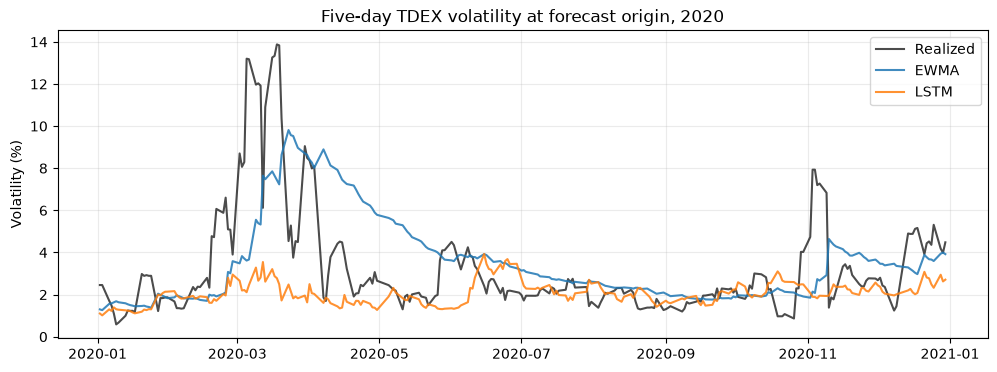

In [9]:
plot_dates = test_dates[test_dates.year == 2020]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(plot_dates, market_targets.loc[plot_dates, "realized_vol"], label="Realized", color="black", alpha=0.7)
for model in ("EWMA", "LSTM"):
    ax.plot(plot_dates, vol_forecasts.loc[plot_dates, model], label=model, alpha=0.85)
ax.set(title="Five-day TDEX volatility at forecast origin, 2020", ylabel="Volatility (%)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 6. เงินลงทุนได้ประโยชน์ไหม

เปรียบเทียบกับ Equal Weight และ Historical Inverse Volatility ในช่วง 2018–2024 พอร์ต **Forecast Inverse Vol** ใช้ EWMA หรือ LightGBM รายหุ้นแทน vol ย้อนหลัง พอร์ต **Vol Target EW** ใช้ forecast ตลาดหาระดับ exposure ของพอร์ต Equal Weight จากอัตรา `target / forecast` จำกัดสูงสุดที่ 100% ส่วนที่เหลือเป็นเงินสดที่สมมติผลตอบแทน 0% ระดับ target ใช้มัธยฐานของ realized vol ใน validation มีสองกรณีให้เทียบ คือโมเดลที่เลือกจาก validation และ LSTM โดยตรง

เพื่อให้สั่งปรับพอร์ตได้ทันราคาปิดก่อนเริ่มเดือนใหม่ ใช้ข้อมูลและ forecast จากสิ้นวันซื้อขายก่อนวันส่งคำสั่งหนึ่งวัน แล้วเริ่มนับผลตอบแทน close-to-close ในวันซื้อขายแรกของเดือนใหม่ ทุกพอร์ตจำลอง daily return ด้วยน้ำหนักเป้าหมายเดิมภายในเดือน ใช้ turnover และค่าธรรมเนียม 15 bps ตาม Phase 5 โดย turnover วัดจากการเปลี่ยนน้ำหนักหุ้นเป้าหมาย ส่วน risk-free 2.5% ใช้สำหรับคำนวณ Sharpe เท่านั้น สัญญาณ 5 วันถูกนำไปใช้กำหนดน้ำหนักรายเดือน จึงเป็นการทดลองประโยชน์ของสัญญาณระยะสั้นกับกติกาที่คงรอบปรับพอร์ตเดิม

In [10]:
target_vol = float(market_targets.loc[validation_dates, "realized_vol"].median())
cost_rate = 0.0015
months = stocks.resample("ME").last().index
portfolio_names = [
    "EW", "Historical IV", "Forecast IV (EWMA)", "Forecast IV (LightGBM)",
    "Vol Target EW (selected)", "Vol Target EW (LSTM)",
]
previous_weights = {name: pd.Series(0.0, index=stocks.columns) for name in portfolio_names}
net_months, rebalance_records = [], []
first_rebalance_weights = None


def weights_from_forecast(forecast_vol):
    inverse = 1 / forecast_vol.clip(lower=1e-6)
    return inverse / inverse.sum()


for i in range(36, len(months)):
    train_end, test_end = months[i - 1], months[i]
    train_start = train_end - pd.offsets.MonthEnd(36)
    train = stocks.loc[(stocks.index > train_start) & (stocks.index <= train_end)]
    period = stocks.loc[(stocks.index > train_end) & (stocks.index <= test_end)]
    signal_date, execution_date = train.index[-2:]
    train = train.loc[:signal_date]
    assert signal_date < execution_date < period.index[0]

    stock_signal = asset_forecasts.loc[signal_date].reindex(stocks.columns)
    market_signals = vol_forecasts.loc[signal_date, [selected_vol_model, "LSTM"]]
    selected_exposure, lstm_exposure = (target_vol / market_signals.clip(lower=1e-6)).clip(upper=1)
    equal_weights = get_equal_weights(train)
    weights = {
        "EW": equal_weights,
        "Historical IV": get_inverse_vol_weights(train),
        "Forecast IV (EWMA)": weights_from_forecast(stock_signal["EWMA"]),
        "Forecast IV (LightGBM)": weights_from_forecast(stock_signal["LightGBM"]),
        "Vol Target EW (selected)": equal_weights * selected_exposure,
        "Vol Target EW (LSTM)": equal_weights * lstm_exposure,
    }

    if first_rebalance_weights is None:
        first_rebalance_weights = pd.DataFrame({
            "EWMA forecast vol (%)": stock_signal["EWMA"],
            "LightGBM forecast vol (%)": stock_signal["LightGBM"],
            "Historical IV weight (%)": weights["Historical IV"] * 100,
            "Forecast IV (EWMA) weight (%)": weights["Forecast IV (EWMA)"] * 100,
            "Forecast IV (LightGBM) weight (%)": weights["Forecast IV (LightGBM)"] * 100,
        })
    net = pd.DataFrame(index=period.index)
    for name, weight in weights.items():
        turn = (weight - previous_weights[name]).abs().sum() / 2
        cost = turn * cost_rate
        daily = period @ weight
        daily.iloc[0] -= cost
        net[name] = daily
        rebalance_records.append({
            "strategy": name, "signal_date": signal_date, "execution_date": execution_date,
            "first_held_date": period.index[0],
            "exposure": weight.sum(), "turnover": turn, "cost": cost,
        })
        previous_weights[name] = weight
    net["TDEX"] = returns.loc[period.index, "TDEX.BK"]
    net_months.append(net)

portfolio_net = pd.concat(net_months)
rebalance = pd.DataFrame(rebalance_records)
assert portfolio_net.index.equals(stocks.loc[TEST_START:].index)
assert not portfolio_net.isna().any().any()
assert (rebalance["signal_date"] < rebalance["execution_date"]).all()
assert (rebalance["execution_date"] < rebalance["first_held_date"]).all()
assert rebalance["exposure"].between(0, 1 + 1e-12).all()
print(f"Volatility target {target_vol:.2f}% ต่อ 5 วัน | โมเดลที่ใช้ {selected_vol_model}")
print(f"ทดสอบ {len(net_months)} เดือน, {len(portfolio_net):,} วันซื้อขาย")
display(rebalance.head(len(portfolio_names)).round({"exposure": 4, "turnover": 4, "cost": 6}))

print("รอบแรก: จาก vol รายหุ้นไปเป็นน้ำหนัก โดยใช้ 1 / vol แล้วหารให้ผลรวมเป็น 100%")
display(first_rebalance_weights.head(6).round(3))
print("ผลรวมน้ำหนักทุกหุ้น (%)")
display(first_rebalance_weights.filter(like="weight").sum().round(3).to_frame("Weight sum (%)"))
print("รอบแรก: จาก forecast ตลาดไปเป็นสัดส่วนหุ้นและเงินสด")
first_signal_date = rebalance["signal_date"].iloc[0]
targeting_models = pd.Series({
    "Validation-selected": selected_vol_model,
    "LSTM": "LSTM",
}, name="โมเดล")
first_market_vol = targeting_models.map(vol_forecasts.loc[first_signal_date])
first_exposure = (target_vol / first_market_vol).clip(upper=1)
display(pd.DataFrame({
    "โมเดล": targeting_models,
    "Target vol (%)": target_vol,
    "Forecast vol (%)": first_market_vol,
    "หุ้น (%)": first_exposure * 100,
    "เงินสด (%)": (1 - first_exposure) * 100,
}).round(3))

Volatility target 0.75% ต่อ 5 วัน | โมเดลที่ใช้ Historical
ทดสอบ 84 เดือน, 1,700 วันซื้อขาย


,strategy,signal_date,execution_date,first_held_date,exposure,turnover,cost
0,EW,2017-12-28,2017-12-29,2018-01-03,1.0000,0.5000,0.000750
1,Historical IV,2017-12-28,2017-12-29,2018-01-03,1.0000,0.5000,0.000750
2,Forecast IV (EWMA),2017-12-28,2017-12-29,2018-01-03,1.0000,0.5000,0.000750
3,Forecast IV (LightGBM),2017-12-28,2017-12-29,2018-01-03,1.0000,0.5000,0.000750
4,Vol Target EW (selected),2017-12-28,2017-12-29,2018-01-03,0.8357,0.4179,0.000627
5,Vol Target EW (LSTM),2017-12-28,2017-12-29,2018-01-03,0.6226,0.3113,0.000467


รอบแรก: จาก vol รายหุ้นไปเป็นน้ำหนัก โดยใช้ 1 / vol แล้วหารให้ผลรวมเป็น 100%


,EWMA forecast vol (%),LightGBM forecast vol (%),Historical IV weight (%),Forecast IV (EWMA) weight (%),Forecast IV (LightGBM) weight (%)
ticker,,,,,
ADVANC.BK,2.512,2.500,5.661,6.388,6.140
AOT.BK,3.331,3.040,6.615,4.817,5.049
BBL.BK,2.057,2.018,8.244,7.801,7.607
BDMS.BK,2.461,2.376,7.905,6.521,6.460
BH.BK,3.378,3.195,5.419,4.750,4.804
BJC.BK,4.185,3.240,4.865,3.834,4.738


ผลรวมน้ำหนักทุกหุ้น (%)


,Weight sum (%)
Historical IV weight (%),100.0
Forecast IV (EWMA) weight (%),100.0
Forecast IV (LightGBM) weight (%),100.0


รอบแรก: จาก forecast ตลาดไปเป็นสัดส่วนหุ้นและเงินสด


,โมเดล,Target vol (%),Forecast vol (%),หุ้น (%),เงินสด (%)
Validation-selected,Historical,0.751,0.899,83.572,16.428
LSTM,LSTM,0.751,1.206,62.265,37.735


พอร์ตหลังหักค่าธรรมเนียม


,Net CAGR (%),Annual Vol (%),Sharpe (Rf=2.5%),Max Drawdown (%),Annual Turnover (%)
EW,5.420,17.484,0.247,-44.022,7.143
Forecast IV (EWMA),2.315,16.761,0.072,-44.452,104.120
Forecast IV (LightGBM),3.138,16.874,0.120,-43.930,93.064
Historical IV,3.364,16.845,0.133,-43.569,13.754
TDEX,1.628,15.365,0.020,-36.533,NaN
Vol Target EW (LSTM),1.918,8.200,-0.032,-23.214,81.514
Vol Target EW (selected),1.413,7.100,-0.119,-20.361,90.271


Forecast IV (EWMA) เทียบ Historical IV | CAGR -1.05 pp | Sharpe -0.061 | Max Drawdown -0.88 pp
Forecast IV (LightGBM) เทียบ Historical IV | CAGR -0.23 pp | Sharpe -0.013 | Max Drawdown -0.36 pp
Vol Target EW (selected) เทียบ EW | CAGR -4.01 pp | Sharpe -0.366 | Max Drawdown +23.66 pp
Vol Target EW (LSTM) เทียบ EW | CAGR -3.50 pp | Sharpe -0.279 | Max Drawdown +20.81 pp


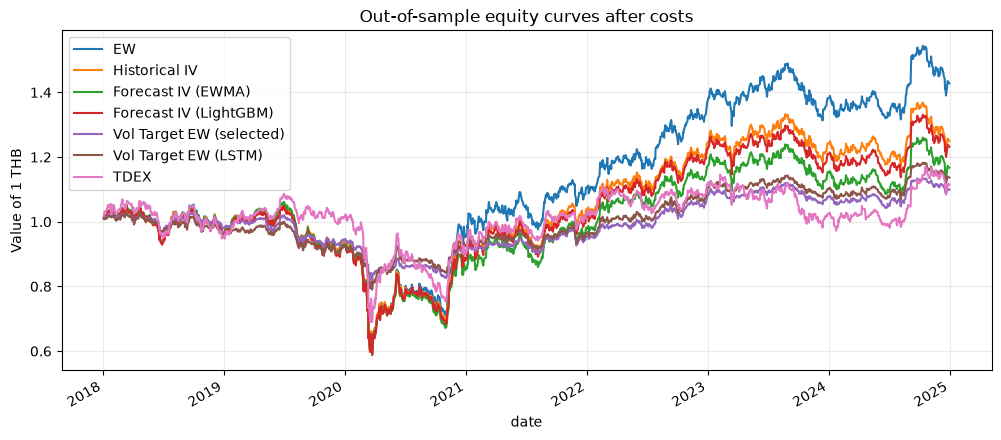

ตัวอย่างการอ่าน equity curve: ผลตอบแทนสุทธิรายวันและมูลค่าเงิน 1 บาทของ LSTM


,Daily net return (%),เงินสะสม (บาท)
date,,
2018-01-03,0.83953,1.00840
2018-01-04,0.37438,1.01217
2018-01-05,-0.20296,1.01012
2018-01-08,-0.13348,1.00877
2018-01-09,0.07496,1.00952


In [11]:
years = len(portfolio_net) / 252
equity = (1 + portfolio_net).cumprod()
portfolio_result = pd.DataFrame({
    "Net CAGR (%)": (equity.iloc[-1].pow(1 / years) - 1) * 100,
    "Annual Vol (%)": calculate_annualized_volatility(portfolio_net) * 100,
    "Sharpe (Rf=2.5%)": calculate_sharpe_ratio(portfolio_net, risk_free_rate=0.025),
    "Max Drawdown (%)": calculate_max_drawdown(portfolio_net) * 100,
    "Annual Turnover (%)": rebalance.groupby("strategy")["turnover"].mean() * 1200,
})
print("พอร์ตหลังหักค่าธรรมเนียม")
display(portfolio_result.round(3))
for strategy, baseline in [
    ("Forecast IV (EWMA)", "Historical IV"),
    ("Forecast IV (LightGBM)", "Historical IV"),
    ("Vol Target EW (selected)", "EW"),
    ("Vol Target EW (LSTM)", "EW"),
]:
    delta = portfolio_result.loc[strategy] - portfolio_result.loc[baseline]
    print(
        f"{strategy} เทียบ {baseline} | CAGR {delta['Net CAGR (%)']:+.2f} pp "
        f"| Sharpe {delta['Sharpe (Rf=2.5%)']:+.3f} "
        f"| Max Drawdown {delta['Max Drawdown (%)']:+.2f} pp"
    )

fig, ax = plt.subplots(figsize=(12, 5))
equity.plot(ax=ax, title="Out-of-sample equity curves after costs", ylabel="Value of 1 THB")
ax.grid(alpha=0.25)
plt.show()

print("ตัวอย่างการอ่าน equity curve: ผลตอบแทนสุทธิรายวันและมูลค่าเงิน 1 บาทของ LSTM")
lstmp = "Vol Target EW (LSTM)"
display(pd.DataFrame({
    "Daily net return (%)": portfolio_net[lstmp] * 100,
    "เงินสะสม (บาท)": equity[lstmp],
}).head(5).round(5))

### โน้ตเตรียมสัมภาษณ์: Historical เทียบกับ LSTM ใน Volatility Targeting

ทั้งสองพอร์ตแบ่งเงินในหุ้นเท่ากัน และใช้กติกาเดียวกันคือเอาเป้าหมายความผันผวนหารด้วยค่าพยากรณ์เพื่อกำหนดสัดส่วนหุ้น ส่วนที่เหลือถือเงินสด ตารางนี้เทียบกับ EW ที่ถือหุ้นเต็ม 100%

| ค่าพยากรณ์ที่ใช้ปรับสัดส่วนหุ้น | ขนาด Max Drawdown ลดลง | Net CAGR ลดลง |
|---|---:|---:|
| Historical (เลือกจาก validation) | 23.66 จุดเปอร์เซ็นต์ | 4.01 จุดเปอร์เซ็นต์ |
| LSTM | 20.81 จุดเปอร์เซ็นต์ | 3.50 จุดเปอร์เซ็นต์ |

> ใน backtest นี้ Historical ลด drawdown ได้มากกว่า ส่วน LSTM รักษาผลตอบแทนทบต้นหลังค่าธรรมเนียมได้มากกว่าเมื่อเทียบกัน ถ้าโจทย์ให้น้ำหนักกับการลด drawdown ผลชุดนี้เอนไปทาง Historical ถ้าให้น้ำหนักกับการรักษา CAGR ผลจะเอนไปทาง LSTM ทั้งสองพอร์ตมี CAGR ต่ำกว่า EW ที่ถือหุ้นเต็ม


In [12]:
print(f"โมเดล volatility ที่ QLIKE ต่ำสุดบน test: {vol_test.index[0]}")
print(f"LSTM เทียบ EWMA — ส่วนต่าง QLIKE {vol_test.loc['LSTM', 'QLIKE'] - vol_test.loc['EWMA', 'QLIKE']:+.4f}")
print(f"โมเดลทิศทาง AUC สูงสุดบน test: {direction_test['AUC'].idxmax()}")
print(
    "LSTM accuracy เทียบ Always up — "
    f"{direction_test.loc['LSTM', 'vs Always up (pp)']:+.2f} pp, "
    f"95% CI [{direction_test.loc['LSTM', 'CI 95% lower (pp)']:+.2f}, "
    f"{direction_test.loc['LSTM', 'CI 95% upper (pp)']:+.2f}] pp"
)

โมเดล volatility ที่ QLIKE ต่ำสุดบน test: GARCH
LSTM เทียบ EWMA — ส่วนต่าง QLIKE +0.3177
โมเดลทิศทาง AUC สูงสุดบน test: LightGBM
LSTM accuracy เทียบ Always up — -2.60 pp, 95% CI [-7.14, +1.89] pp


## 7. ทบทวนก่อนเล่าโปรเจกต์

- ลองชี้ว่า `shift(-k)` ใช้สร้าง target ตรงไหน และโมเดลถูกกันออกจากข้อมูลอนาคตอย่างไร
- เปรียบเทียบ LSTM กับ EWMA และ GARCH บนวันเดียวกัน แล้วดูว่าอันดับตาม MSE กับ QLIKE เหมือนกันไหม
- แยกข้อสรุปเรื่องค่าคลาดเคลื่อนของ forecast ออกจากผลพอร์ตหลังค่าธรรมเนียม การเปลี่ยน exposure มีผลทั้งกับผลตอบแทนและ drawdown
- หุ้นเป็นชุดคงที่ ใช้ TDEX เป็นตัวแทนตลาด และฝึก LSTM ด้วยข้อมูลรายวันจำนวนจำกัด ผลจึงขึ้นกับช่วงข้อมูลและสมมติฐานเหล่านี้

ย้อนดูตารางตามเส้นทางนี้เมื่ออ่านโค้ด: วันและราคา → ผลตอบแทน 5 วันในอนาคต → target → รอบฝึกและวันออก forecast → คะแนน → น้ำหนักและมูลค่าพอร์ต